In [34]:
%pip install yfinance
import yfinance as yf
import pandas as pd
import os

sp500=yf.Ticker("^GSPC")
sp500=sp500.history(period="max")

Note: you may need to restart the kernel to use updated packages.


In [35]:
sp500

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,0.0,0.0
1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,0.0,0.0
1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,0.0,0.0
1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,0.0,0.0
1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,0.0,0.0
...,...,...,...,...,...,...,...
2026-10-16 00:00:00-04:00,7745.319824,7756.839844,7631.770020,7659.439941,5482060000,0.0,0.0
2026-10-19 00:00:00-04:00,7702.770020,7731.180176,7684.790039,7690.729980,4587260000,0.0,0.0
2026-10-20 00:00:00-04:00,7679.009766,7748.419922,7668.029785,7712.569824,5004770000,0.0,0.0


In [36]:
sp500.index

DatetimeIndex(['1927-12-30 00:00:00-05:00', '1928-01-03 00:00:00-05:00',
               '1928-01-04 00:00:00-05:00', '1928-01-05 00:00:00-05:00',
               '1928-01-06 00:00:00-05:00', '1928-01-09 00:00:00-05:00',
               '1928-01-10 00:00:00-05:00', '1928-01-11 00:00:00-05:00',
               '1928-01-12 00:00:00-05:00', '1928-01-13 00:00:00-05:00',
               ...
               '2026-10-09 00:00:00-04:00', '2026-10-12 00:00:00-04:00',
               '2026-10-13 00:00:00-04:00', '2026-10-14 00:00:00-04:00',
               '2026-10-15 00:00:00-04:00', '2026-10-16 00:00:00-04:00',
               '2026-10-19 00:00:00-04:00', '2026-10-20 00:00:00-04:00',
               '2026-10-21 00:00:00-04:00', '2026-10-22 00:00:00-04:00'],
              dtype='datetime64[ns, America/New_York]', name='Date', length=24820, freq=None)

<Axes: xlabel='Date'>

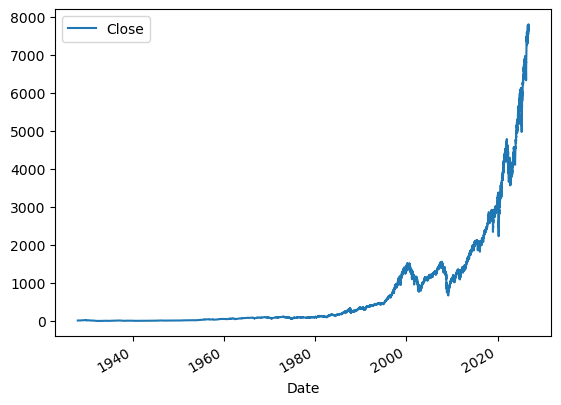

In [37]:
sp500.plot.line(y="Close",use_index=True)

In [38]:
del sp500["Dividends"]
del sp500["Stock Splits"]

In [39]:
sp500

,Open,High,Low,Close,Volume
Date,,,,,
1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0
1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0
1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0
1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0
1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0
...,...,...,...,...,...
2026-10-16 00:00:00-04:00,7745.319824,7756.839844,7631.770020,7659.439941,5482060000
2026-10-19 00:00:00-04:00,7702.770020,7731.180176,7684.790039,7690.729980,4587260000
2026-10-20 00:00:00-04:00,7679.009766,7748.419922,7668.029785,7712.569824,5004770000


In [40]:
sp500["Tomorrow"]=sp500["Close"].shift(-1)

In [41]:
sp500["Target"]=(sp500["Tomorrow"]>sp500["Close"]).astype(int)

In [42]:
sp500

,Open,High,Low,Close,Volume,Tomorrow,Target
Date,,,,,,,
1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.760000,1
1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,17.719999,0
1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,17.549999,0
1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,17.660000,1
1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.500000,0
...,...,...,...,...,...,...,...
2026-10-16 00:00:00-04:00,7745.319824,7756.839844,7631.770020,7659.439941,5482060000,7690.729980,1
2026-10-19 00:00:00-04:00,7702.770020,7731.180176,7684.790039,7690.729980,4587260000,7712.569824,1
2026-10-20 00:00:00-04:00,7679.009766,7748.419922,7668.029785,7712.569824,5004770000,7757.169922,1


In [43]:
sp500=sp500["1990-01-01":].copy()

In [44]:
sp500

,Open,High,Low,Close,Volume,Tomorrow,Target
Date,,,,,,,
1990-01-02 00:00:00-05:00,353.399994,359.690002,351.980011,359.690002,162070000,358.760010,0
1990-01-03 00:00:00-05:00,359.690002,360.589996,357.890015,358.760010,192330000,355.670013,0
1990-01-04 00:00:00-05:00,358.760010,358.760010,352.890015,355.670013,177000000,352.200012,0
1990-01-05 00:00:00-05:00,355.670013,355.670013,351.350006,352.200012,158530000,353.790009,1
1990-01-08 00:00:00-05:00,352.200012,354.239990,350.540009,353.790009,140110000,349.619995,0
...,...,...,...,...,...,...,...
2026-10-16 00:00:00-04:00,7745.319824,7756.839844,7631.770020,7659.439941,5482060000,7690.729980,1
2026-10-19 00:00:00-04:00,7702.770020,7731.180176,7684.790039,7690.729980,4587260000,7712.569824,1
2026-10-20 00:00:00-04:00,7679.009766,7748.419922,7668.029785,7712.569824,5004770000,7757.169922,1


In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

Target
1    4972
0    4298
Name: count, dtype: int64
Target
1    53.635383
0    46.364617
Name: proportion, dtype: float64


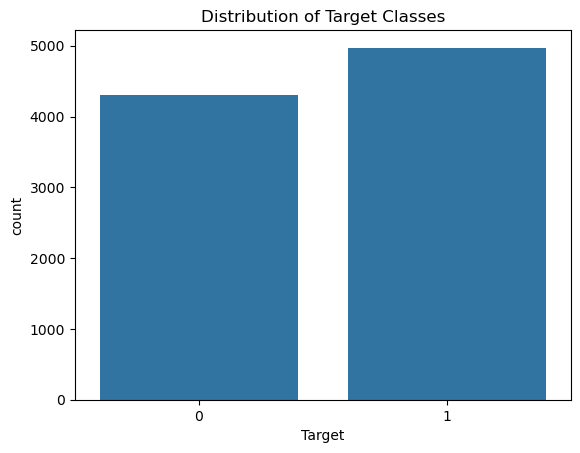

In [46]:
counts = sp500["Target"].value_counts()
percentages = sp500["Target"].value_counts(normalize=True) * 100

print(counts)
print(percentages)

sns.countplot(data=sp500, x="Target")
plt.title("Distribution of Target Classes")
plt.show()

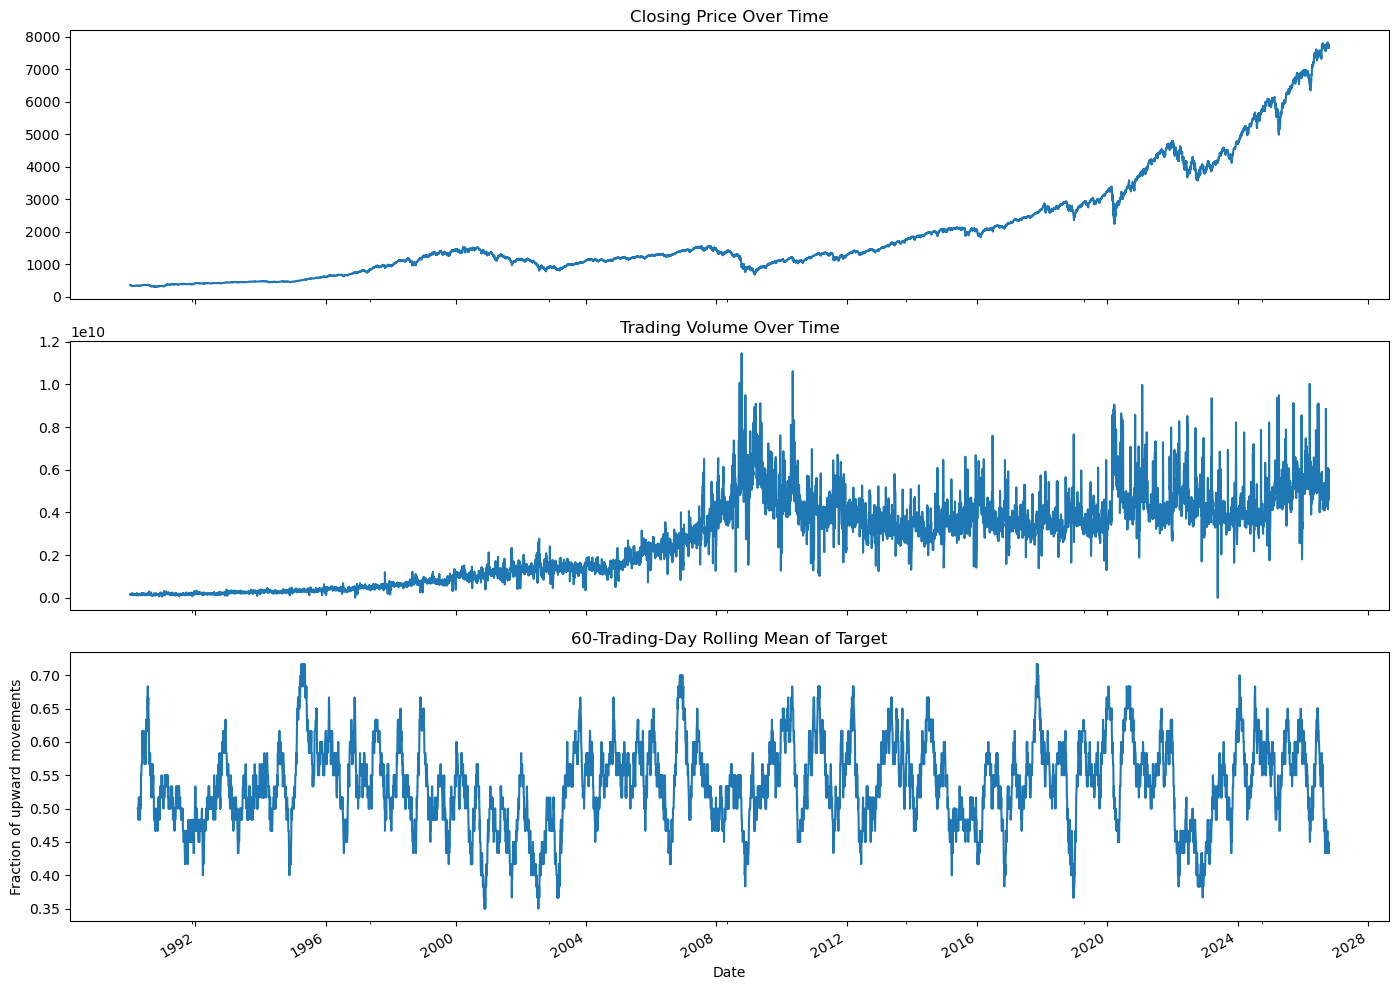

In [47]:
sp500.index = pd.to_datetime(sp500.index)
sp500 = sp500.sort_index()

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

sp500["Close"].plot(ax=axes[0], title="Closing Price Over Time")
sp500["Volume"].plot(ax=axes[1], title="Trading Volume Over Time")

sp500["Target"].rolling(60).mean().plot(ax=axes[2])
axes[2].set_title("60-Trading-Day Rolling Mean of Target")
axes[2].set_ylabel("Fraction of upward movements")

plt.tight_layout()
plt.show()

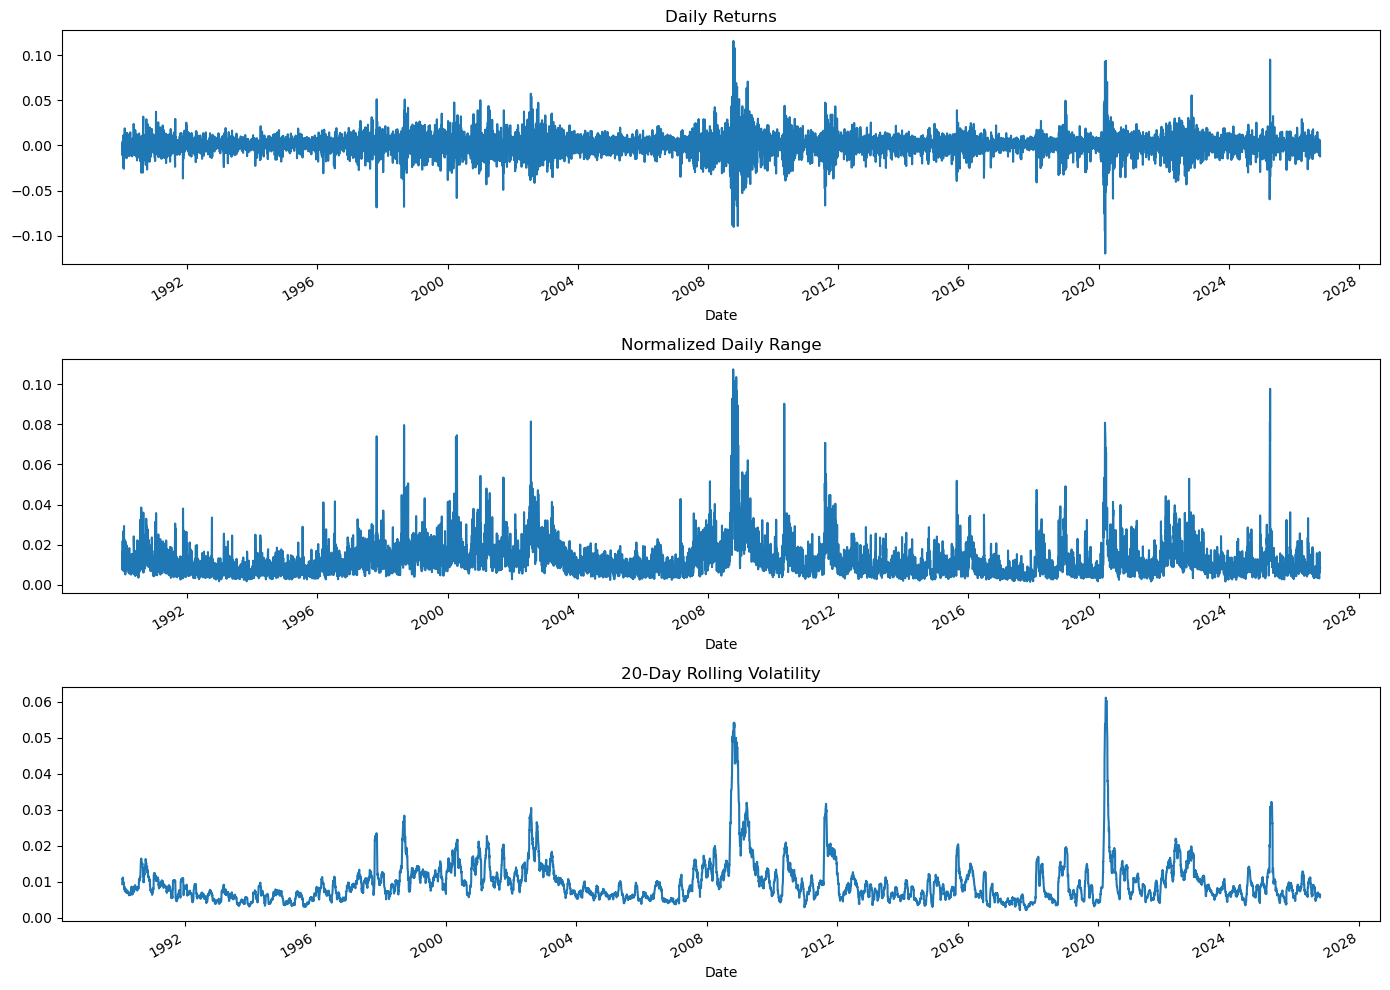

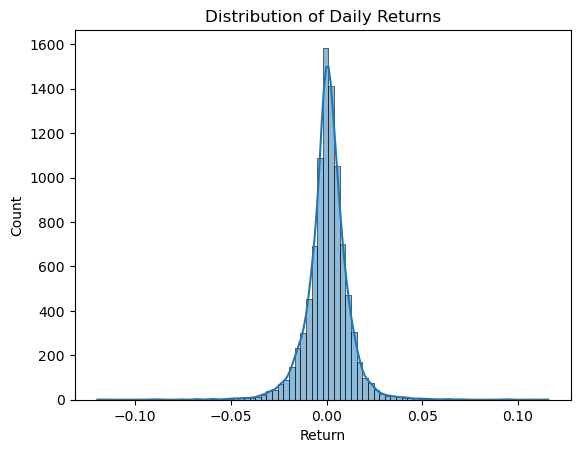

In [48]:
sp500["Return"] = sp500["Close"].pct_change()
sp500["Daily_Range"] = (
    sp500["High"] - sp500["Low"]
) / sp500["Close"]

sp500["Volatility_20"] = (
    sp500["Return"].rolling(20).std()
)

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

sp500["Return"].plot(ax=axes[0], title="Daily Returns")
sp500["Daily_Range"].plot(ax=axes[1], title="Normalized Daily Range")
sp500["Volatility_20"].plot(ax=axes[2], title="20-Day Rolling Volatility")

plt.tight_layout()
plt.show()

sns.histplot(sp500["Return"].dropna(), bins=80, kde=True)
plt.title("Distribution of Daily Returns")
plt.show()

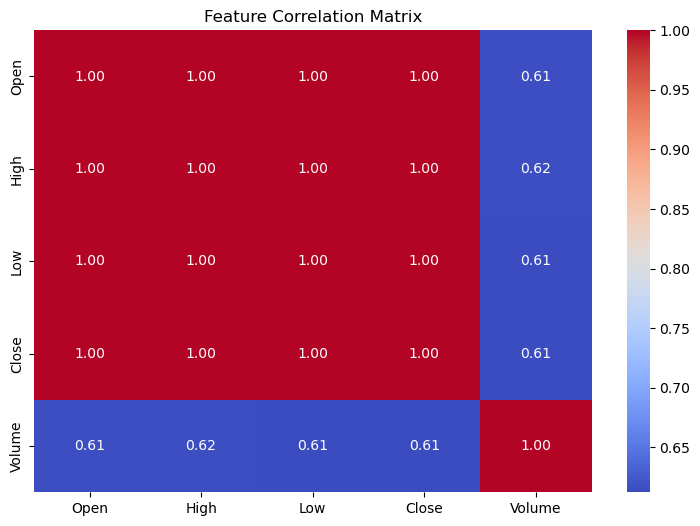

In [49]:
features = ["Open", "High", "Low", "Close", "Volume"]

corr = sp500[features].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

In [50]:
sp500.groupby("Target")[features].mean()

,Open,High,Low,Close,Volume
Target,,,,,
0,1929.456789,1940.609500,1918.001440,1930.454906,2.606520e+09
1,1944.907800,1955.650144,1933.029401,1944.769576,2.659915e+09


In [51]:
from sklearn.ensemble import RandomForestClassifier
model=RandomForestClassifier(n_estimators=100,min_samples_split=100,random_state=1)
train=sp500.iloc[:-100]
test=sp500.iloc[-100:]
Predictors=["Close","Volume","Open","High","Low"]

In [52]:
model.fit(train[Predictors],train["Target"])

RandomForestClassifier(min_samples_split=100, random_state=1)

In [53]:
from sklearn.metrics import precision_score
preds=model.predict(test[Predictors])

In [54]:
preds=pd.Series(preds,index=test.index)

In [55]:
preds

Date
2026-06-02 00:00:00-04:00    1
2026-06-03 00:00:00-04:00    1
2026-06-04 00:00:00-04:00    1
2026-06-05 00:00:00-04:00    1
2026-06-08 00:00:00-04:00    1
                            ..
2026-10-16 00:00:00-04:00    1
2026-10-19 00:00:00-04:00    1
2026-10-20 00:00:00-04:00    1
2026-10-21 00:00:00-04:00    1
2026-10-22 00:00:00-04:00    1
Length: 100, dtype: int64

In [56]:
precision_score(test["Target"],preds)

0.45

<Axes: xlabel='Date'>

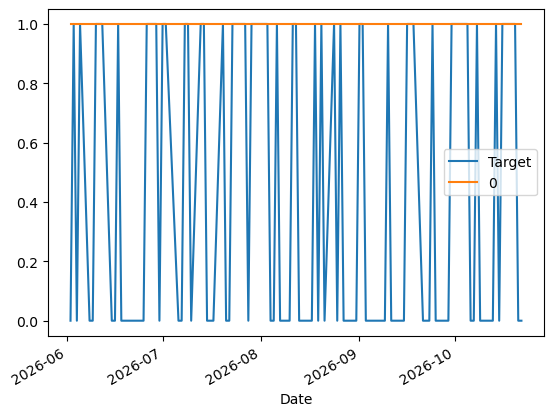

In [57]:
combine=pd.concat([test["Target"],preds],axis=1)
combine.plot()

In [58]:
def predict(train, test, predictors, model):
    model.fit(train[predictors], train["Target"])
    preds = model.predict(test[predictors])
    preds = pd.Series(preds, index=test.index, name="Predictions")
    combined = pd.concat([test["Target"], preds], axis=1)
    return combined

In [59]:
def backtest(data, model, predictors, start=2500, step=250):
    all_predictions = []

    for i in range(start, data.shape[0], step):
        train = data.iloc[0:i].copy()
        test = data.iloc[i:(i+step)].copy()
        predictions = predict(train, test, predictors, model)
        all_predictions.append(predictions)
    
    return pd.concat(all_predictions)

In [60]:
predictions = backtest(sp500, model, Predictors)

In [61]:
predictions["Predictions"].value_counts()

Predictions
0    4082
1    2688
Name: count, dtype: int64

In [62]:
precision_score(predictions["Target"], predictions["Predictions"])

0.5316220238095238

In [63]:
predictions["Target"].value_counts() / predictions.shape[0]

Target
1    0.53678
0    0.46322
Name: count, dtype: float64

In [64]:
horizons = [2,5,60,250,1000]
new_predictors = []

for horizon in horizons:
    rolling_averages = sp500.rolling(horizon).mean()
    
    ratio_column = f"Close_Ratio_{horizon}"
    sp500[ratio_column] = sp500["Close"] / rolling_averages["Close"]
    
    trend_column = f"Trend_{horizon}"
    sp500[trend_column] = sp500.shift(1).rolling(horizon).sum()["Target"]
    
    new_predictors+= [ratio_column, trend_column]

In [65]:
sp500 = sp500.dropna(subset=sp500.columns[sp500.columns != "Tomorrow"])

In [66]:
sp500

,Open,High,Low,Close,Volume,Tomorrow,Target,Return,Daily_Range,Volatility_20,Close_Ratio_2,Trend_2,Close_Ratio_5,Trend_5,Close_Ratio_60,Trend_60,Close_Ratio_250,Trend_250,Close_Ratio_1000,Trend_1000
Date,,,,,,,,,,,,,,,,,,,,
1993-12-14 00:00:00-05:00,465.730011,466.119995,462.459991,463.059998,275050000,461.839996,0,-0.005669,0.007904,0.003714,0.997157,1.0,0.996617,1.0,1.000283,32.0,1.028047,127.0,1.176082,512.0
1993-12-15 00:00:00-05:00,463.059998,463.690002,461.839996,461.839996,331770000,463.339996,1,-0.002635,0.004006,0.003419,0.998681,0.0,0.995899,1.0,0.997329,32.0,1.025151,126.0,1.172676,512.0
1993-12-16 00:00:00-05:00,461.859985,463.980011,461.859985,463.339996,284620000,466.380005,1,0.003248,0.004576,0.003407,1.001621,1.0,0.999495,2.0,1.000311,32.0,1.028274,127.0,1.176163,513.0
1993-12-17 00:00:00-05:00,463.339996,466.380005,463.339996,466.380005,363750000,465.850006,0,0.006561,0.006518,0.003668,1.003270,2.0,1.004991,3.0,1.006561,32.0,1.034781,128.0,1.183537,514.0
1993-12-20 00:00:00-05:00,466.380005,466.899994,465.529999,465.850006,255900000,465.299988,0,-0.001136,0.002941,0.003637,0.999431,1.0,1.003784,2.0,1.005120,32.0,1.033359,128.0,1.181856,513.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-16 00:00:00-04:00,7745.319824,7756.839844,7631.770020,7659.439941,5482060000,7690.729980,1,-0.010927,0.016329,0.006588,0.994506,1.0,0.988694,1.0,0.997780,27.0,1.067188,132.0,1.360045,547.0
2026-10-19 00:00:00-04:00,7702.770020,7731.180176,7684.790039,7690.729980,4587260000,7712.569824,1,0.004085,0.006032,0.005686,1.002038,1.0,0.995728,2.0,1.001250,27.0,1.070977,132.0,1.364647,547.0
2026-10-20 00:00:00-04:00,7679.009766,7748.419922,7668.029785,7712.569824,5004770000,7757.169922,1,0.002840,0.010423,0.005734,1.001418,2.0,1.000963,3.0,1.003442,27.0,1.073434,132.0,1.367572,547.0


In [67]:
model = RandomForestClassifier(n_estimators=200, min_samples_split=50, random_state=1)

In [68]:
def predict(train, test, predictors, model):
    model.fit(train[predictors], train["Target"])
    preds = model.predict_proba(test[predictors])[:,1]
    preds[preds >=.6] = 1
    preds[preds <.6] = 0
    preds = pd.Series(preds, index=test.index, name="Predictions")
    combined = pd.concat([test["Target"], preds], axis=1)
    return combined

In [69]:
predictions = backtest(sp500, model, new_predictors)

In [70]:
predictions["Predictions"].value_counts()

Predictions
0.0    4886
1.0     884
Name: count, dtype: int64

In [71]:
precision_score(predictions["Target"], predictions["Predictions"])

0.5746606334841629

In [72]:
predictions["Target"].value_counts() / predictions.shape[0]

Target
1    0.545754
0    0.454246
Name: count, dtype: float64

In [73]:
predictions

,Target,Predictions
Date,,
2003-11-14 00:00:00-05:00,0,0.0
2003-11-17 00:00:00-05:00,0,1.0
2003-11-18 00:00:00-05:00,1,1.0
2003-11-19 00:00:00-05:00,0,0.0
2003-11-20 00:00:00-05:00,1,1.0
...,...,...
2026-10-16 00:00:00-04:00,1,0.0
2026-10-19 00:00:00-04:00,1,0.0
2026-10-20 00:00:00-04:00,1,0.0
